# 印度二手车市场 EDA：价格、车龄与品牌

**数据**：Kaggle *Used Car Price Dataset*，印度二手车挂牌记录，原始 7,400 行 × 29 列。

**分析目标**

1. 价格分布长什么样？应该用什么评估指标？
2. 车龄、里程、品牌、燃油/变速箱/车身分别如何影响价格？
3. 数据里有哪些缺失、异常和时间口径问题？
4. 这些发现对后续建模有什么启示？

**关键口径**

- 数据是 **2019–2021 年**的挂牌记录，其中 6,377 条集中在 2021 年。
- 车龄 = **挂牌年份 − 制造年份**，不能用当前年份减，否则会整体高估 5 年。
- 价格单位是**印度卢比（INR）**，图表里用“万 INR”表示。

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")

plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "Arial Unicode MS"]
plt.rcParams["axes.unicode_minus"] = False
sns.set_theme(style="whitegrid", font="Microsoft YaHei")

# 兼容从项目根目录或 notebooks/ 目录执行
BASE = Path.cwd()
if not (BASE / "data").exists():
    BASE = BASE.parent
DATA_PATH = BASE / "data" / "raw" / "car_data.csv"
FIG_DIR = BASE / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

print("项目根目录:", BASE)
print("数据文件:", DATA_PATH)
print("图表输出:", FIG_DIR)

项目根目录: D:\xiaochejiage\车辆预测\car_price_project
数据文件: D:\xiaochejiage\车辆预测\car_price_project\data\raw\car_data.csv
图表输出: D:\xiaochejiage\车辆预测\car_price_project\reports\figures


## 1. 加载与清洗

清洗规则：

- 删除重复记录
- 价格必须大于 0 且小于 1000 万 INR
- 里程必须大于 0
- 制造年份不能早于 1980，也不能晚于挂牌年份
- 类别字段统一小写、去空格；缺失值单独记为 `unknown`，不直接丢弃

In [2]:
raw = pd.read_csv(DATA_PATH)
print(f"原始数据: {raw.shape[0]} 行 × {raw.shape[1]} 列")

df = raw.copy()
df["ad_year"] = pd.to_datetime(df["ad_created_on"], errors="coerce").dt.year
n_missing_ad = int(df["ad_year"].isna().sum())
df = df[df["ad_year"].notna()]

n_before = len(df)
df = df.drop_duplicates()
n_dup = n_before - len(df)

df = df[(df["sale_price"] > 0) & (df["sale_price"] < 10_000_000) & (df["kms_run"] > 0)]
df = df[(df["yr_mfr"] >= 1980) & (df["yr_mfr"] <= df["ad_year"])]

CAT_COLS = ["make", "fuel_type", "transmission", "body_type"]
for c in CAT_COLS:
    df[c] = df[c].astype("string").str.strip().str.lower().fillna("unknown")

df["Car_Age"] = df["ad_year"] - df["yr_mfr"]
df["price_wan"] = df["sale_price"] / 10_000
df["log_price"] = np.log1p(df["sale_price"])

overview = pd.DataFrame(
    {
        "项目": [
            "原始行数",
            "缺失挂牌时间",
            "重复行",
            "清洗后行数",
            "挂牌年份范围",
            "车龄范围",
            "价格中位数",
            "价格均值",
        ],
        "值": [
            f"{len(raw):,}",
            f"{n_missing_ad}",
            f"{n_dup}",
            f"{len(df):,}",
            f"{int(df.ad_year.min())}–{int(df.ad_year.max())}",
            f"{int(df.Car_Age.min())}–{int(df.Car_Age.max())} 年",
            f"{df.sale_price.median():,.0f} INR",
            f"{df.sale_price.mean():,.0f} INR",
        ],
    }
)
display(overview)

原始数据: 7400 行 × 29 列


,项目,值
0,原始行数,"7,400"
1,缺失挂牌时间,5
2,重复行,1
3,清洗后行数,"7,391"
4,挂牌年份范围,2019–2021
5,车龄范围,0–24 年
6,价格中位数,"382,499 INR"
7,价格均值,"455,002 INR"


## 2. 数据质量：缺失与异常

`original_price` 缺失超过 40%，基本不能作为建模特征；`transmission` 和 `body_type` 也有少量缺失，后面统一记为 `unknown`，避免直接删行导致样本损失。

,缺失数,缺失比例(%)
original_price,3280,44.3
car_availability,620,8.4
transmission,556,7.5
source,126,1.7
body_type,103,1.4
registered_city,10,0.1
registered_state,10,0.1
car_rating,9,0.1
fitness_certificate,8,0.1
ad_created_on,1,0.0


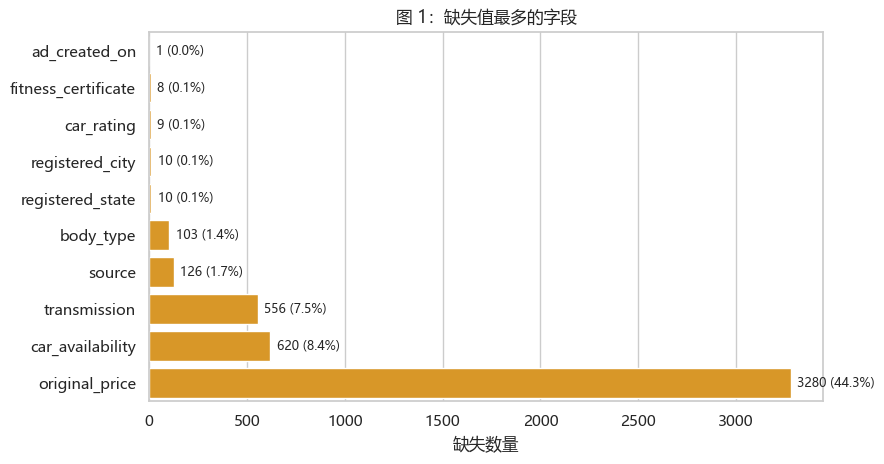

In [3]:
missing = raw.isna().sum().sort_values(ascending=False)
missing = missing[missing > 0]

missing_df = pd.DataFrame(
    {
        "缺失数": missing,
        "缺失比例(%)": (missing / len(raw) * 100).round(1),
    }
)
display(missing_df.head(12))

fig, ax = plt.subplots(figsize=(9, 4.8))
plot_data = missing.head(12).sort_values()
sns.barplot(x=plot_data.values, y=plot_data.index, ax=ax, color="#f59e0b")
ax.set_title("图 1：缺失值最多的字段")
ax.set_xlabel("缺失数量")
ax.set_ylabel("")
for i, v in enumerate(plot_data.values):
    ax.text(v + plot_data.max() * 0.01, i, f"{v} ({v / len(raw) * 100:.1f}%)", va="center", fontsize=9)
plt.tight_layout()
plt.savefig(FIG_DIR / "01_missing_values.png", dpi=150, bbox_inches="tight")
plt.show()

## 3. 价格分布：明显右偏

原始价格均值高于中位数，说明长尾高价车拉高了均值。右偏会让平方误差类指标偏向高价样本，因此后续评估要同时看 **MAE / MAPE**，而不只看 R²。

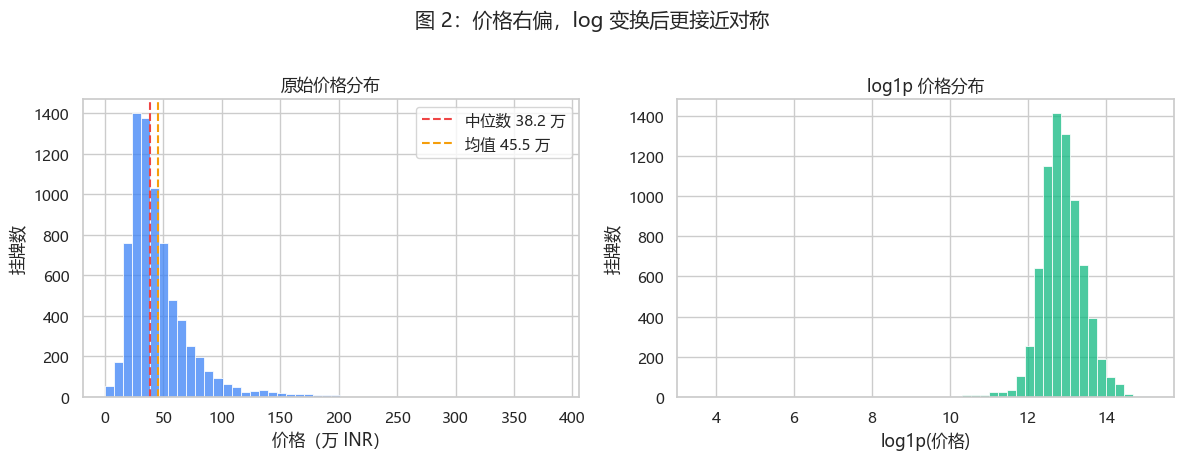

价格偏度：原始 2.77 | log -0.72
中位数 382,499 INR | 均值 455,002 INR


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

sns.histplot(df["price_wan"], bins=50, ax=axes[0], color="#3b82f6")
axes[0].axvline(df.price_wan.median(), color="#ef4444", linestyle="--",
                label=f"中位数 {df.price_wan.median():.1f} 万")
axes[0].axvline(df.price_wan.mean(), color="#f59e0b", linestyle="--",
                label=f"均值 {df.price_wan.mean():.1f} 万")
axes[0].set_title("原始价格分布")
axes[0].set_xlabel("价格（万 INR）")
axes[0].set_ylabel("挂牌数")
axes[0].legend()

sns.histplot(df["log_price"], bins=50, ax=axes[1], color="#10b981")
axes[1].set_title("log1p 价格分布")
axes[1].set_xlabel("log1p(价格)")
axes[1].set_ylabel("挂牌数")

plt.suptitle("图 2：价格右偏，log 变换后更接近对称", y=1.02)
plt.tight_layout()
plt.savefig(FIG_DIR / "02_price_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"价格偏度：原始 {df.sale_price.skew():.2f} | log {df.log_price.skew():.2f}")
print(f"中位数 {df.sale_price.median():,.0f} INR | 均值 {df.sale_price.mean():,.0f} INR")

## 4. 车龄：最强的价格驱动因素

按挂牌年份计算车龄后，中位价从 0–3 年的约 **62.8 万** 降到 7–10 年的约 **33.9 万**，再降到 11–15 年的约 **22.9 万**。15 年以上只有 12 条，不能据此下结论。

也就是说，0–3 年到 7–10 年中位价下降约 **46%**，到 11–15 年下降约 **64%**。

车龄与价格的相关系数为 **-0.515**，是所有数值特征里最强的。

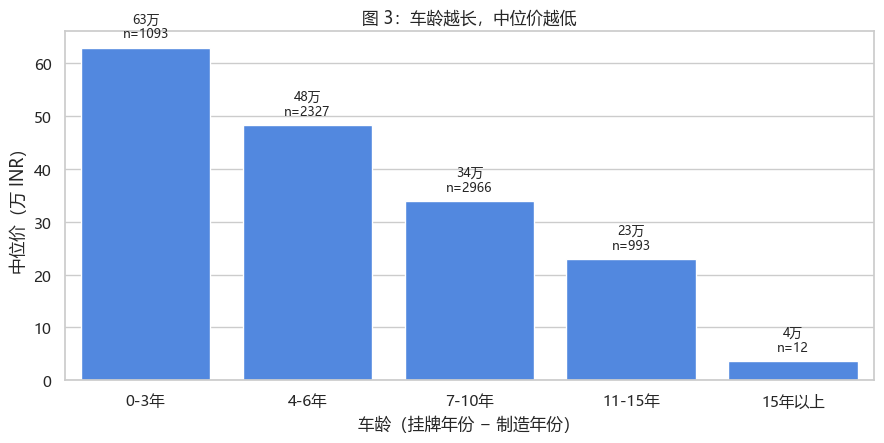

,age_band,count,median_wan
0,0-3年,1093,62.8499
1,4-6年,2327,48.1899
2,7-10年,2966,33.8549
3,11-15年,993,22.8699
4,15年以上,12,3.6000


车龄与价格相关系数: -0.515


In [5]:
bins = [-1, 3, 6, 10, 15, 100]
labels = ["0-3年", "4-6年", "7-10年", "11-15年", "15年以上"]
df["age_band"] = pd.cut(df["Car_Age"], bins=bins, labels=labels)

age_stats = (
    df.groupby("age_band", observed=True)["sale_price"]
    .agg(["count", "median"])
    .reset_index()
)
age_stats["median_wan"] = age_stats["median"] / 10_000

fig, ax = plt.subplots(figsize=(9, 4.6))
sns.barplot(data=age_stats, x="age_band", y="median_wan", ax=ax, color="#3b82f6")
ax.set_title("图 3：车龄越长，中位价越低")
ax.set_xlabel("车龄（挂牌年份 − 制造年份）")
ax.set_ylabel("中位价（万 INR）")
for i, row in age_stats.iterrows():
    ax.text(i, row.median_wan + 2, f"{row.median_wan:.0f}万\nn={row['count']}",
            ha="center", fontsize=9)
plt.tight_layout()
plt.savefig(FIG_DIR / "03_price_by_age.png", dpi=150, bbox_inches="tight")
plt.show()

display(age_stats[["age_band", "count", "median_wan"]])
print("车龄与价格相关系数:", round(df.sale_price.corr(df.Car_Age), 3))

## 5. 里程：影响弱且非单调

里程与价格的相关系数只有 **-0.105**。分段中位价从 0–2 万的约 49.2 万降到 10–15 万的约 34.4 万，但 15 万以上又回升到约 38.7 万。这更可能是样本量小、车龄/品牌混杂造成的，而不是“里程越高越值钱”。

结论：里程不能单独用来定价，必须和车龄、品牌一起看。

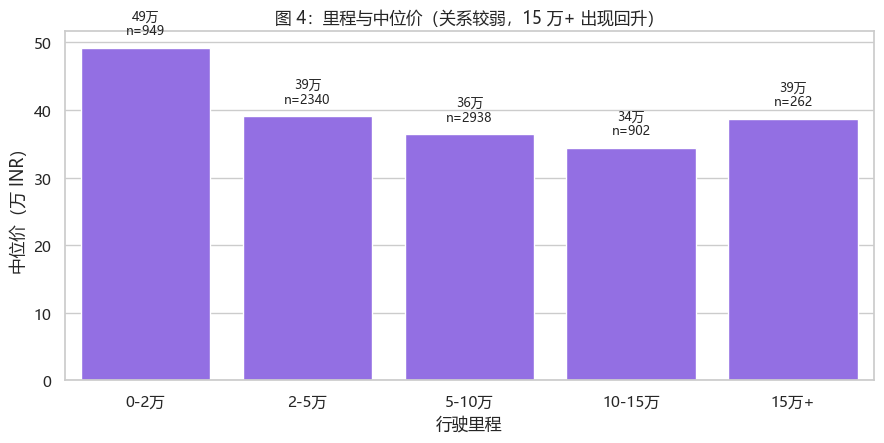

,km_band,count,median_wan
0,0-2万,949,49.1899
1,2-5万,2340,39.0799
2,5-10万,2938,36.4299
3,10-15万,902,34.4049
4,15万+,262,38.6949


里程与价格相关系数: -0.105


In [6]:
bins = [-1, 20000, 50000, 100000, 150000, 10**9]
labels = ["0-2万", "2-5万", "5-10万", "10-15万", "15万+"]
df["km_band"] = pd.cut(df["kms_run"], bins=bins, labels=labels)

km_stats = (
    df.groupby("km_band", observed=True)["sale_price"]
    .agg(["count", "median"])
    .reset_index()
)
km_stats["median_wan"] = km_stats["median"] / 10_000

fig, ax = plt.subplots(figsize=(9, 4.6))
sns.barplot(data=km_stats, x="km_band", y="median_wan", ax=ax, color="#8b5cf6")
ax.set_title("图 4：里程与中位价（关系较弱，15 万+ 出现回升）")
ax.set_xlabel("行驶里程")
ax.set_ylabel("中位价（万 INR）")
for i, row in km_stats.iterrows():
    ax.text(i, row.median_wan + 2, f"{row.median_wan:.0f}万\nn={row['count']}",
            ha="center", fontsize=9)
plt.tight_layout()
plt.savefig(FIG_DIR / "04_price_by_mileage.png", dpi=150, bbox_inches="tight")
plt.show()

display(km_stats[["km_band", "count", "median_wan"]])
print("里程与价格相关系数:", round(df.sale_price.corr(df.kms_run), 3))

## 6. 品牌：要看中位价，也要看样本量

挂牌量高度集中在 Maruti（3,175）和 Hyundai（1,798）。Toyota、Honda、Mahindra 的中位价更高；豪华品牌中位价很高，但样本极少（Mercedes 39、BMW 33、Audi 27、Volvo 3），均值/中位价都不稳定，不能直接下“品牌溢价”结论。

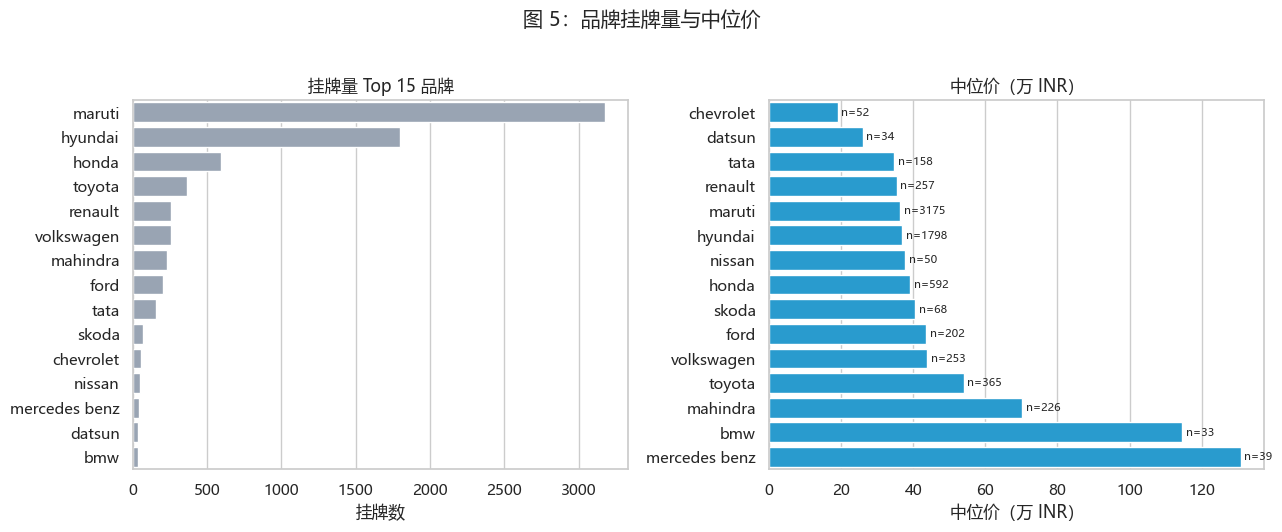

,count,median,median_wan
make,,,
maruti,3175,364399.0,36.43990
hyundai,1798,368649.0,36.86490
honda,592,391999.0,39.19990
toyota,365,540000.0,54.00000
renault,257,354199.0,35.41990
volkswagen,253,438799.0,43.87990
mahindra,226,702749.5,70.27495
ford,202,435449.5,43.54495
tata,158,346499.0,34.64990


In [7]:
top_brands = df["make"].value_counts().head(15)
brand_stats = (
    df[df["make"].isin(top_brands.index)]
    .groupby("make")["sale_price"]
    .agg(["count", "median"])
)
brand_stats["median_wan"] = brand_stats["median"] / 10_000
brand_stats = brand_stats.sort_values("median_wan")

fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))

sns.barplot(x=top_brands.values, y=top_brands.index, ax=axes[0], color="#94a3b8")
axes[0].set_title("挂牌量 Top 15 品牌")
axes[0].set_xlabel("挂牌数")
axes[0].set_ylabel("")

sns.barplot(data=brand_stats.reset_index(), x="median_wan", y="make",
            ax=axes[1], color="#0ea5e9")
axes[1].set_title("中位价（万 INR）")
axes[1].set_xlabel("中位价（万 INR）")
axes[1].set_ylabel("")
for i, row in enumerate(brand_stats.itertuples()):
    axes[1].text(row.median_wan + 1, i, f"n={row.count}", va="center", fontsize=8)

plt.suptitle("图 5：品牌挂牌量与中位价", y=1.02)
plt.tight_layout()
plt.savefig(FIG_DIR / "05_brand_analysis.png", dpi=150, bbox_inches="tight")
plt.show()

display(brand_stats.sort_values("count", ascending=False))

## 7. 燃油、变速箱、车身类型

- 柴油中位价约 **51.5 万**，明显高于汽油的约 **35.1 万**
- 自动挡约 **58.2 万**，高于手动挡的约 **36.0 万**
- SUV（约 67.2 万）、豪华 SUV（约 100 万）远高于 hatchback（约 32.3 万）

这些差异**不是因果**：柴油车、自动挡、SUV 往往同时是更贵的品牌和更新的车。建模时要让模型同时控制车龄、品牌和里程。

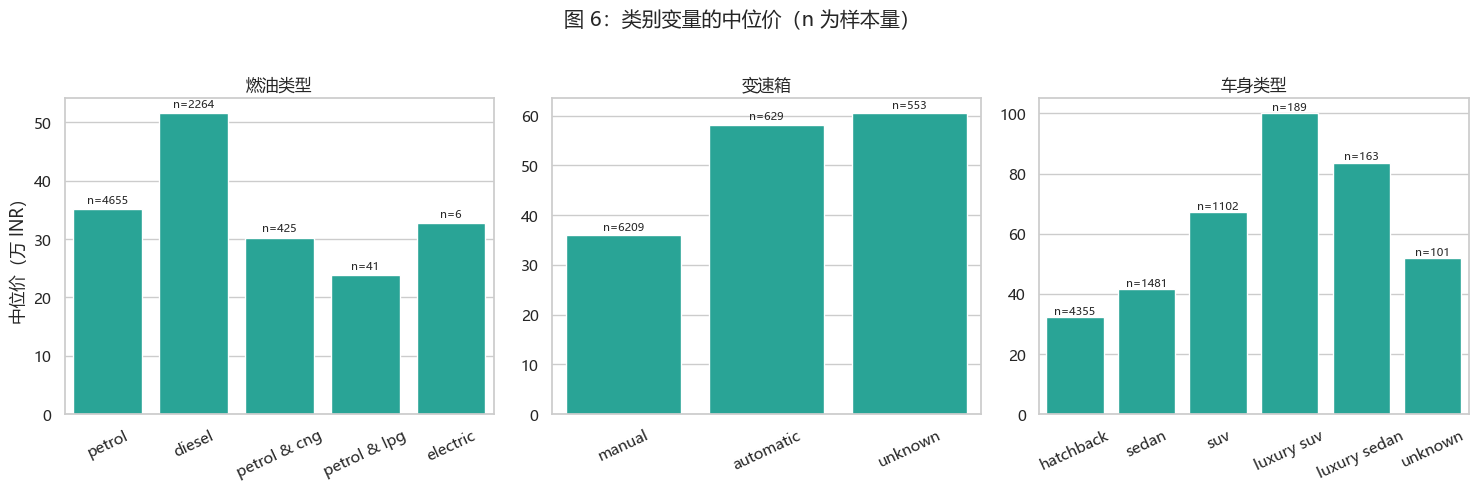

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))
configs = [
    ("fuel_type", "燃油类型"),
    ("transmission", "变速箱"),
    ("body_type", "车身类型"),
]

for ax, (col, title) in zip(axes, configs):
    stats = (
        df.groupby(col)["sale_price"]
        .agg(["count", "median"])
        .sort_values("count", ascending=False)
    )
    stats["median_wan"] = stats["median"] / 10_000
    sns.barplot(data=stats.reset_index(), x=col, y="median_wan", ax=ax, color="#14b8a6")
    ax.set_title(title)
    ax.set_xlabel("")
    ax.set_ylabel("中位价（万 INR）" if col == "fuel_type" else "")
    ax.tick_params(axis="x", rotation=25)
    for i, row in enumerate(stats.itertuples()):
        ax.text(i, row.median_wan + 1, f"n={row.count}", ha="center", fontsize=8)

plt.suptitle("图 6：类别变量的中位价（n 为样本量）", y=1.02)
plt.tight_layout()
plt.savefig(FIG_DIR / "06_category_effects.png", dpi=150, bbox_inches="tight")
plt.show()

## 8. 相关性：车龄是核心，里程信号很弱

`Car_Age` 与价格的相关系数为 **-0.515**，`kms_run` 只有 **-0.105**。`yr_mfr` 与 `Car_Age` 完全共线（一个加、一个减），建模时**只保留 `Car_Age`**，不要同时放两个。

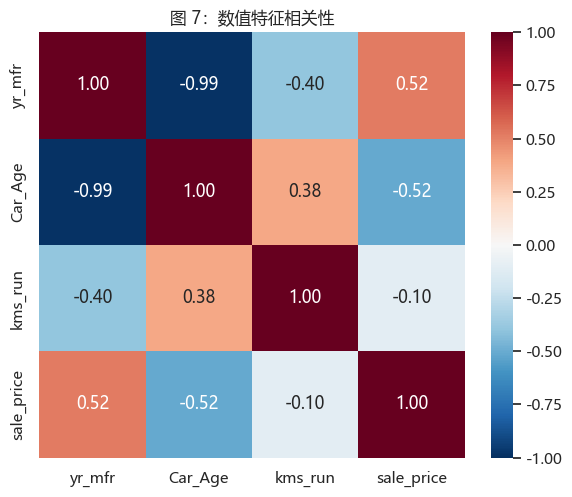

sale_price    1.000000
yr_mfr        0.519053
kms_run      -0.104848
Car_Age      -0.515149
Name: sale_price, dtype: float64

In [9]:
corr_cols = ["yr_mfr", "Car_Age", "kms_run", "sale_price"]
corr = df[corr_cols].corr()

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0,
            vmin=-1, vmax=1, square=True, ax=ax)
ax.set_title("图 7：数值特征相关性")
plt.tight_layout()
plt.savefig(FIG_DIR / "07_correlation_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

display(corr["sale_price"].sort_values(ascending=False))

## 9. 主要结论

1. **价格右偏**：中位数 38.2 万 INR，均值 45.5 万 INR，偏度约 2.77。评估时不能只看 R²，要同时看 MAE / MAPE。
2. **车龄是最强驱动因素**：与价格相关系数 -0.515；0–3 年中位价 62.8 万，7–10 年降到 33.9 万，11–15 年降到 22.9 万。
3. **里程影响弱且非单调**：相关系数 -0.105；15 万公里以上中位价回升，主要是样本少和混杂因素，不能解释为“里程越高越值钱”。
4. **品牌要看样本量**：Maruti / Hyundai 占据大部分挂牌量；Toyota / Honda / Mahindra 中位价更高；豪华品牌样本只有个位数到几十条，结论不稳定。
5. **类别变量有溢价但混杂严重**：柴油、自动挡、SUV 的中位价更高，但它们同时与品牌、车龄相关，不能直接做因果解释。
6. **时间口径很重要**：数据是 2019–2021 年挂牌，车龄必须按挂牌年份计算；模型输出的价格口径是 2021 年 INR，未做通胀调整。

## 10. 对建模的启示

- 用 `Car_Age = ad_year - yr_mfr`，不要用当前年份减制造年份
- 保留 `Car_Age`，去掉 `yr_mfr`，避免完全共线
- 保留 `kms_run` 和衍生特征，但对车龄/里程加单调约束
- 同时报告 R²、RMSE、MAE、MAPE；价格右偏时 MAE/MAPE 更能反映体验
- 类别缺失显式记为 `unknown`，不要静默删行
- 小样本品牌不要过度解读；后续可考虑目标编码或品牌分组